# Predicting Vehicle Prices Using Regression Models

## **Objectives**  
The primary goal of this project is to develop a robust regression model to predict used car prices for a reseller based on various listed features and specifications. In addition to predicting prices, the project focuses on identifying feature importance and mitigating overfitting through the application of regularisation techniques.

There can be several business objectives for this, such as:

* **Price Prediction**: Model car prices based on features like mileage, fuel type, and performance.
* **Market Analysis**: Explore trends and preferences in the used car market, by type, region, or other metrics.
* **Feature Importance**: Identify the most important factors influencing car prices (e.g., fuel type, mileage, age).

### **Tasks Overview**
The data pipeline for this task involves the following steps:  
1. **Dataset Overview**   
2. **Data Preprocessing**
3. **Data Visualisation & Exploration**
4. **Model Building**
3. **Regularisation**

## **1 Data Understanding**

| **Variable** | **Description** |
--------|--------------|
| `make_model` | The brand and model of the vehicle (e.g., 'Audi A1'). |
| `body_type` | The body style of the vehicle, such as Sedan, Compact, or Station Wagon. |
| `price`  | The listed price of the car in currency. |
| `vat`  | Indicates the VAT status for the vehicle's price (e.g., VAT deductible, Price negotiable). |
| `km` | The total mileage (in kilometers) of the vehicle, indicating its usage. |
| `Type` | Condition of the vehicle, whether it's 'Used' or 'New'.|
| `Fuel` | Type of fuel the vehicle uses, such as 'Diesel', 'Benzine', etc. |
| `Gears` | The number of gears in the vehicle's transmission. |
| `Comfort_Convenience` | Comfort and convenience features, such as 'Air conditioning', 'Leather steering wheel', 'Cruise control', and more. |
| `Entertainment_Media` | Media features available in the vehicle, including 'Bluetooth', 'MP3', 'Radio', etc. |
| `Extras` | Additional features like 'Alloy wheels', 'Sport suspension', etc.|
| `Safety_Security` | Safety features like 'ABS', 'Airbags', 'Electronic stability control', 'Isofix', etc.  |
| `age` | Age of the car (calculated based on the model year). |
| `Previous_Owners`| The number of previous owners the car has had. |
| `hp_kW` | Engine power in kilowatts (kW), indicating the performance capacity of the engine.|
| `Inspection_new` | Indicates whether the car has recently undergone an inspection (1 for yes, 0 for no). |
| `Paint_Type`| The type of paint on the car, such as 'Metallic', 'Matte', etc. |
| `Upholstery_type` | The material used for the interior upholstery, such as 'Cloth', 'Leather', etc.|
| `Gearing_Type` | The type of transmission the car uses, either 'Automatic' or 'Manual'. |
| `Displacement_cc` | The engine displacement in cubic centimeters (cc), indicating the size of the engine.|
| `Weight_kg` | The total weight of the vehicle in kilograms.|
| `Drive_chain` | The type of drivetrain, indicating whether it's 'Front' or 'Rear' wheel drive. |
| `cons_comb`  | The combined fuel consumption in liters per 100 kilometers.|

### **1.1 Data Loading**

**Importing Necessary Libraries**

In [3]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)


#### **1.1.1**
Load the dataset

In [4]:
# Load the data
df = pd.read_csv('Car_Price_data.csv')

In [5]:
pd.set_option("display.max_columns", None)

In [6]:
df.head()

,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,Extras,Safety_Security,age,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Catalytic Converter,Voice Control","ABS,Central door lock,Daytime running lights,D...",3.0,2.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Hil...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Sport seats,Sport suspension,Voic...","ABS,Central door lock,Central door lock with r...",2.0,1.0,141.0,0,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer","Alloy wheels,Voice Control","ABS,Central door lock,Daytime running lights,D...",3.0,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8
3,Audi A1,Sedans,14500,VAT deductible,73000.0,Used,Diesel,6.0,"Air suspension,Armrest,Auxiliary heating,Elect...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport seats,Voice Control","ABS,Alarm system,Central door lock with remote...",3.0,1.0,66.0,0,Metallic,Cloth,Automatic,1422.0,1195.0,front,3.8
4,Audi A1,Sedans,16790,VAT deductible,16200.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport package,Sport suspension,Vo...","ABS,Central door lock,Driver-side airbag,Elect...",3.0,1.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1135.0,front,4.1


In [7]:
df.tail()

,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,Extras,Safety_Security,age,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
15910,Renault Espace,Van,39950,VAT deductible,1647.362609,New,Diesel,6.0,"Air conditioning,Automatic climate control,Cru...","Bluetooth,Digital radio,Hands-free equipment,O...","Alloy wheels,Touch screen","ABS,Central door lock,Central door lock with r...",0.0,1.0,147.0,0,Metallic,Part/Full Leather,Automatic,1997.0,1758.0,front,5.3
15911,Renault Espace,Van,39885,VAT deductible,9900.000000,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Cru...","Bluetooth,Digital radio,Hands-free equipment,R...","Alloy wheels,Touch screen,Voice Control","ABS,Adaptive Cruise Control,Blind spot monitor...",0.0,1.0,165.0,0,Metallic,Cloth,Automatic,1798.0,1708.0,front,7.4
15912,Renault Espace,Van,39875,VAT deductible,15.000000,Pre-registered,Diesel,6.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",Alloy wheels,"ABS,Adaptive Cruise Control,Blind spot monitor...",0.0,1.0,146.0,1,Metallic,Part/Full Leather,Automatic,1997.0,1734.0,front,5.3
15913,Renault Espace,Van,39700,VAT deductible,10.000000,Pre-registered,Diesel,6.0,"Air conditioning,Automatic climate control,Cru...","Bluetooth,Digital radio,Radio,USB","Alloy wheels,Touch screen","ABS,Blind spot monitor,Driver-side airbag,Elec...",0.0,1.0,147.0,0,Metallic,Part/Full Leather,Automatic,1997.0,1758.0,front,5.3
15914,Renault Espace,Van,40999,VAT deductible,1647.362609,Demonstration,Benzine,6.0,"Air conditioning,Automatic climate control,Cru...",USB,"Alloy wheels,Touch screen","ABS,Blind spot monitor,Daytime running lights,...",0.0,1.0,165.0,1,Metallic,Part/Full Leather,Automatic,1798.0,1685.0,4WD,6.8


In [8]:
df.describe().round(2)

,price,km,Gears,age,Previous_Owners,hp_kW,Inspection_new,Displacement_cc,Weight_kg,cons_comb
count,15915.00,15915.00,15915.00,15915.00,15915.00,15915.00,15915.00,15915.00,15915.00,15915.00
mean,18024.38,32090.00,5.94,1.39,1.04,88.50,0.25,1428.66,1337.70,4.83
std,7381.68,36977.21,0.70,1.12,0.34,26.67,0.43,275.80,199.68,0.87
min,4950.00,0.00,5.00,0.00,0.00,40.00,0.00,890.00,840.00,3.00
25%,12850.00,1920.50,5.00,0.00,1.00,66.00,0.00,1229.00,1165.00,4.10
50%,16900.00,20413.00,6.00,1.00,1.00,85.00,0.00,1461.00,1295.00,4.80
75%,21900.00,46900.00,6.00,2.00,1.00,103.00,0.00,1598.00,1472.00,5.40
max,74600.00,317000.00,8.00,3.00,4.00,294.00,1.00,2967.00,2471.00,9.10


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15915 entries, 0 to 15914
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make_model           15915 non-null  str    
 1   body_type            15915 non-null  str    
 2   price                15915 non-null  int64  
 3   vat                  15915 non-null  str    
 4   km                   15915 non-null  float64
 5   Type                 15915 non-null  str    
 6   Fuel                 15915 non-null  str    
 7   Gears                15915 non-null  float64
 8   Comfort_Convenience  15915 non-null  str    
 9   Entertainment_Media  15915 non-null  str    
 10  Extras               15915 non-null  str    
 11  Safety_Security      15915 non-null  str    
 12  age                  15915 non-null  float64
 13  Previous_Owners      15915 non-null  float64
 14  hp_kW                15915 non-null  float64
 15  Inspection_new       15915 non-null  int64  
 1

In [10]:
df.columns = (
    df.columns
      .str.strip()
      .str.lower()
)

## **2 Analysis and Feature Engineering** <font color =red> [35 marks] </font>


### **2.1 Preliminary Analysis and Frequency Distributions** <font color = red> [13 marks] </font>

#### **2.1.1** <font color =red> [1 marks] </font>
Check and fix missing values.

In [11]:
# Find the proportion of missing values in each column and handle if found
# Find the proportion of missing values in each column and handle if found
missing_pct = df.isnull().mean().sort_values(ascending=False) * 100
missing_pct = missing_pct[missing_pct > 0]
print(missing_pct)

Series([], dtype: float64)


In [12]:
df.duplicated().sum()

np.int64(1673)

In [13]:
df = df.drop_duplicates().copy()

In [14]:
df["price"].isna().sum()

np.int64(0)

In [15]:
df["price"].isnull().sum()

np.int64(0)

In [16]:
df["price"].eq(0).sum()

np.int64(0)

**From the features, identify the target feature and numerical and categorical predictors. Select the numerical and categorical features carefully as they will be used in analysis.**

#### **2.1.2** <font color =red> [3 marks] </font>
Identify numerical predictors and plot their frequency distributions.

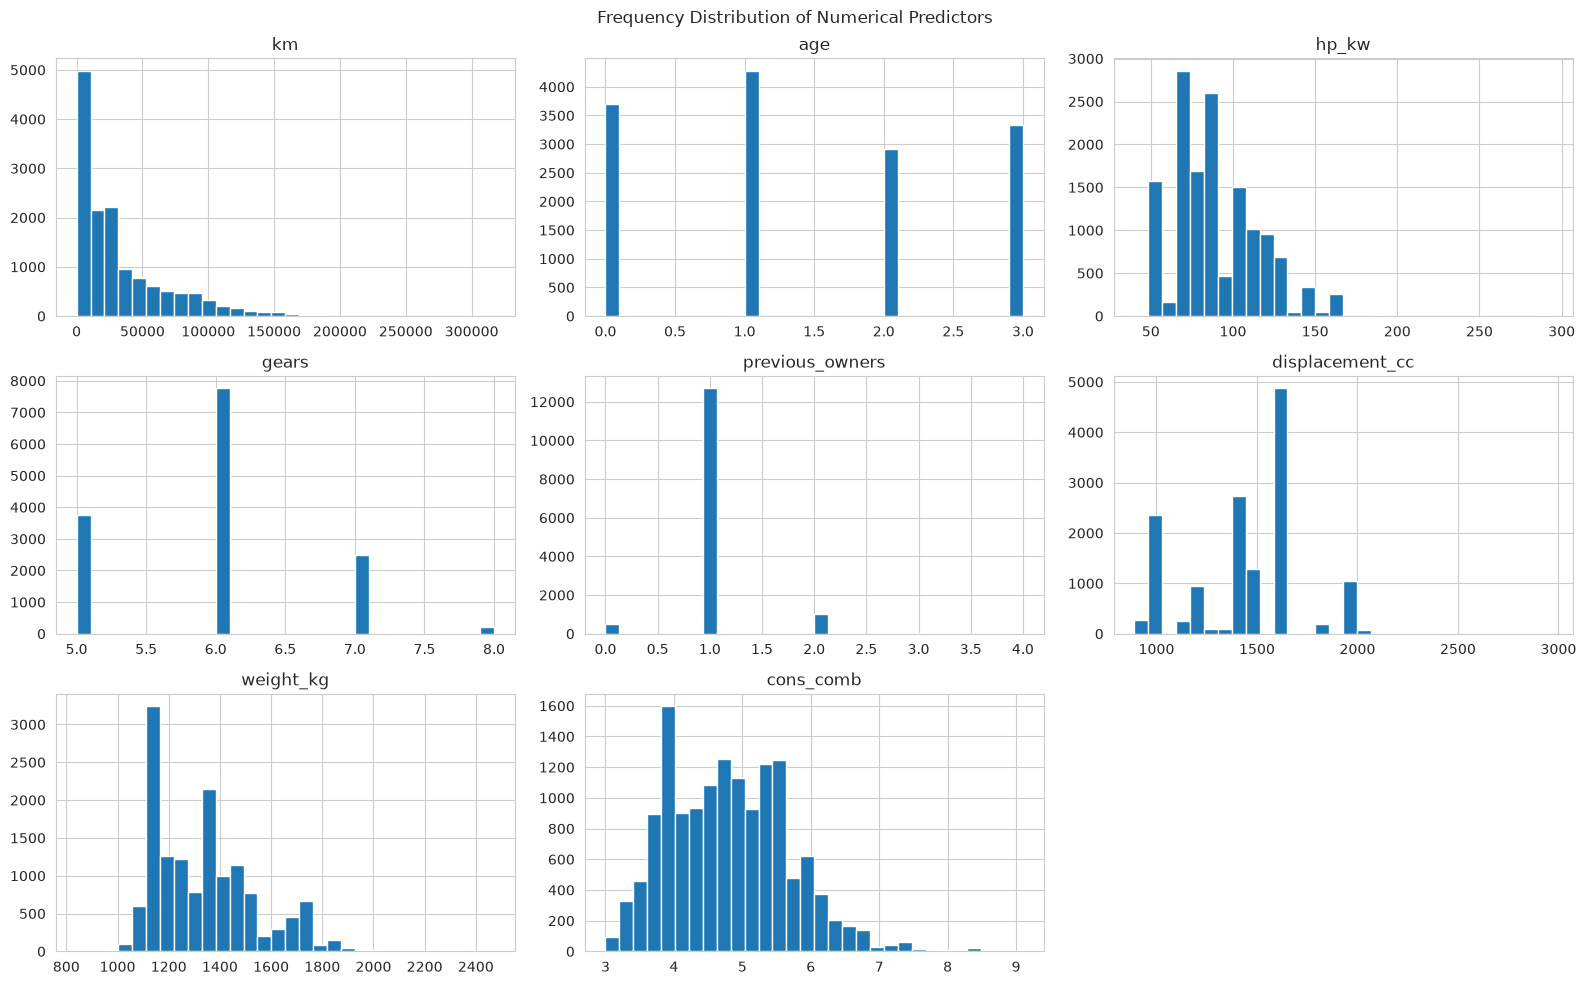

In [17]:
# Identify numerical features and plot histograms
target = 'price'
numerical_features = ['km', 'age', 'hp_kw', 'gears', 'previous_owners',
                       'displacement_cc', 'weight_kg', 'cons_comb']
numerical_features = [c for c in numerical_features if c in df.columns]

df[numerical_features].hist(figsize=(16, 10), bins=30)
plt.suptitle('Frequency Distribution of Numerical Predictors')
plt.tight_layout()
plt.show()

#### **2.1.3** <font color =red> [3 marks] </font>
Identify categorical predictors and plot their frequency distributions.

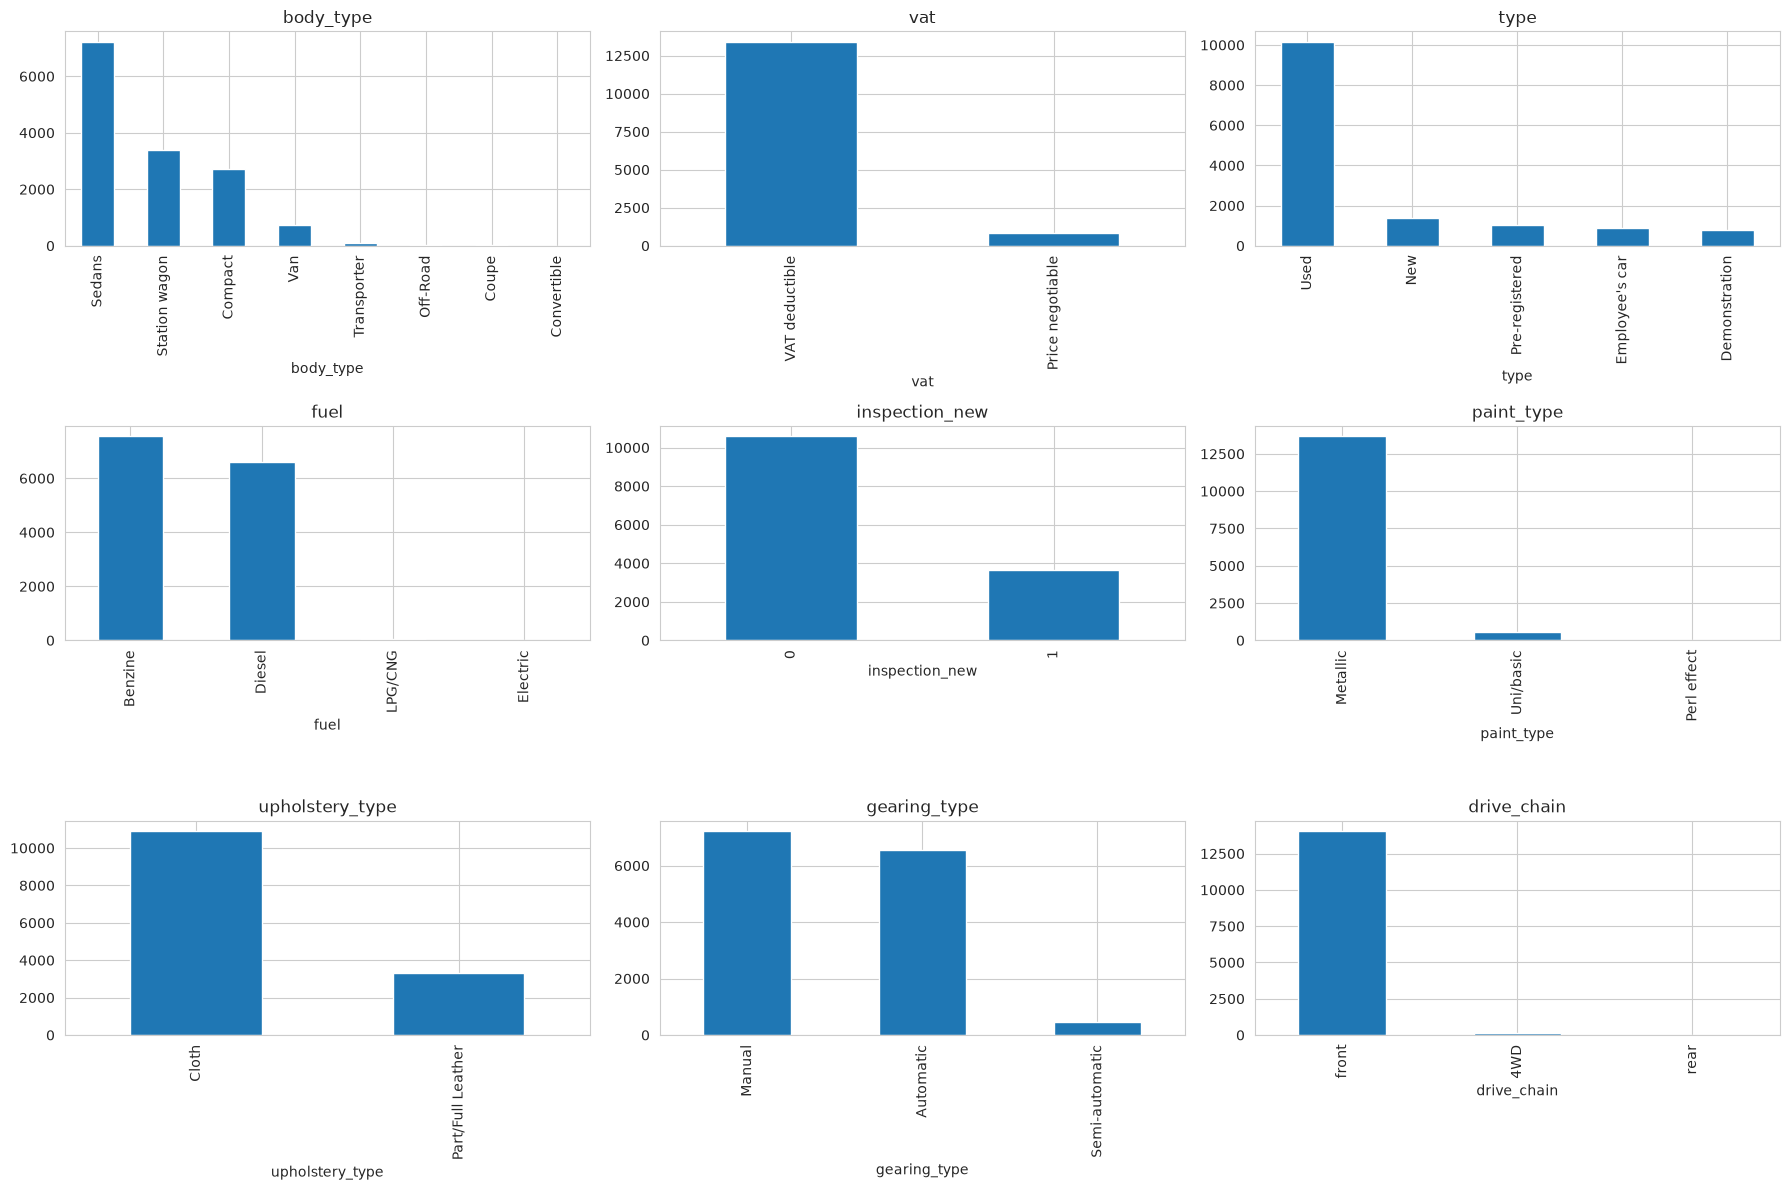

--- body_type ---
body_type
Sedans           50.765342
Station wagon    23.908159
Compact          19.028226
Van               5.160792
Transporter       0.610869
Off-Road          0.294902
Coupe             0.175537
Convertible       0.056172
Name: proportion, dtype: float64

--- vat ---
vat
VAT deductible      94.270468
Price negotiable     5.729532
Name: proportion, dtype: float64

--- type ---
type
Used              71.422553
New                9.612414
Pre-registered     7.225109
Employee's car     6.354445
Demonstration      5.385480
Name: proportion, dtype: float64

--- fuel ---
fuel
Benzine     53.068389
Diesel      46.475214
LPG/CNG      0.421289
Electric     0.035107
Name: proportion, dtype: float64

--- inspection_new ---
inspection_new
0    74.371577
1    25.628423
Name: proportion, dtype: float64

--- paint_type ---
paint_type
Metallic       96.067968
Uni/basic       3.854796
Perl effect     0.077236
Name: proportion, dtype: float64

--- upholstery_type ---
upholstery_type

In [18]:
# Identify categorical columns and check their frequency distributions
# Identify categorical columns and check their frequency distributions
categorical_features = ['body_type', 'vat', 'type', 'fuel', 'inspection_new',
                         'paint_type', 'upholstery_type', 'gearing_type', 'drive_chain']
categorical_features = [c for c in categorical_features if c in df.columns]

fig, axes = plt.subplots(nrows=(len(categorical_features)+2)//3, ncols=3, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(categorical_features):
    df[col].value_counts().plot(kind='bar', ax=axes[i])
    axes[i].set_title(col)
for j in range(i+1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

for col in categorical_features:
    print(f'--- {col} ---')
    print(df[col].value_counts(normalize=True) * 100)
    print()


**Note**: Look carefully at the values stored in columns `["Comfort_Convenience", "Entertainment_Media", "Extras", "Safety_Security"]`.

Should they be considered categorical? Should they be dropped or handled any other way?

#### **2.1.4** <font color =red> [3 marks] </font>
Fix columns with low frequency values and class imbalances.

Some information regarding values in the `Type` column that may help:
- *'Pre-registered'* cars are ones which have already been registered previously by the seller.
- *'New'* cars are not necessarily new cars, but new-like cars. These might also have multiple owners due to multiple pre-registrations as well.
- *'Employee's car'* are cars used by employees over a short period of time and small distance.
- *'Demonstration'* cars are used for trial purposes and also driven for a short time and distance.

Based on these, you can handle this particular column. For other columns, decide a strategy on your own.

In [19]:
# Fix columns as needed
if 'Type' in df.columns:
    print(df['Type'].value_counts())
    type_map = {
        'Used': 'Used',
        'New': 'New',
        'Pre-registered': 'Pre-registered',
        "Employee's car": 'Demonstration',
        'Demonstration': 'Demonstration',
        'Antique': 'New'
    }
    df['Type'] = df['Type'].map(lambda x: type_map.get(x, x))
    print(df['Type'].value_counts())

# For other categorical columns: merge categories below a frequency threshold into 'Other'
threshold = 0.02  # 2%
for col in categorical_features:
    freq = df[col].value_counts(normalize=True)
    rare_labels = freq[freq < threshold].index
    if len(rare_labels) > 0:
        df[col] = df[col].replace(rare_labels, 'Other')

for col in categorical_features:
    print(f'--- {col} after fix ---')
    print(df[col].value_counts(normalize=True) * 100)
    print()



--- body_type after fix ---
body_type
Sedans           50.765342
Station wagon    23.908159
Compact          19.028226
Van               5.160792
Other             1.137481
Name: proportion, dtype: float64

--- vat after fix ---
vat
VAT deductible      94.270468
Price negotiable     5.729532
Name: proportion, dtype: float64

--- type after fix ---
type
Used              71.422553
New                9.612414
Pre-registered     7.225109
Employee's car     6.354445
Demonstration      5.385480
Name: proportion, dtype: float64

--- fuel after fix ---
fuel
Benzine    53.068389
Diesel     46.475214
Other       0.456397
Name: proportion, dtype: float64

--- inspection_new after fix ---
inspection_new
0    74.371577
1    25.628423
Name: proportion, dtype: float64

--- paint_type after fix ---
paint_type
Metallic     96.067968
Uni/basic     3.854796
Other         0.077236
Name: proportion, dtype: float64

--- upholstery_type after fix ---
upholstery_type
Cloth                76.660581
Part/Full 

#### **2.1.5** <font color =red> [3 marks] </font>
Identify target variable and plot the frequency distributions. Apply necessary transformations.

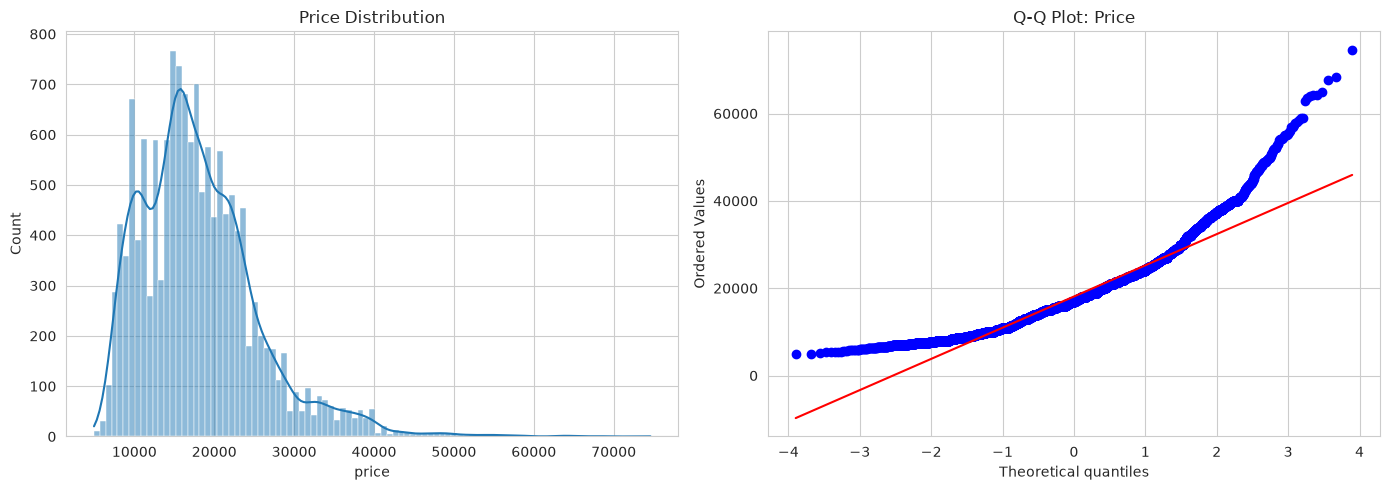

Skewness: 1.2684753766983417


In [20]:
# Plot histograms for target feature
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['price'], kde=True, ax=axes[0])
axes[0].set_title('Price Distribution')
stats.probplot(df['price'], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot: Price')
plt.tight_layout()
plt.show()

print('Skewness:', df['price'].skew())


**The target variable seems to be skewed. Perform suitable transformation on the target.**

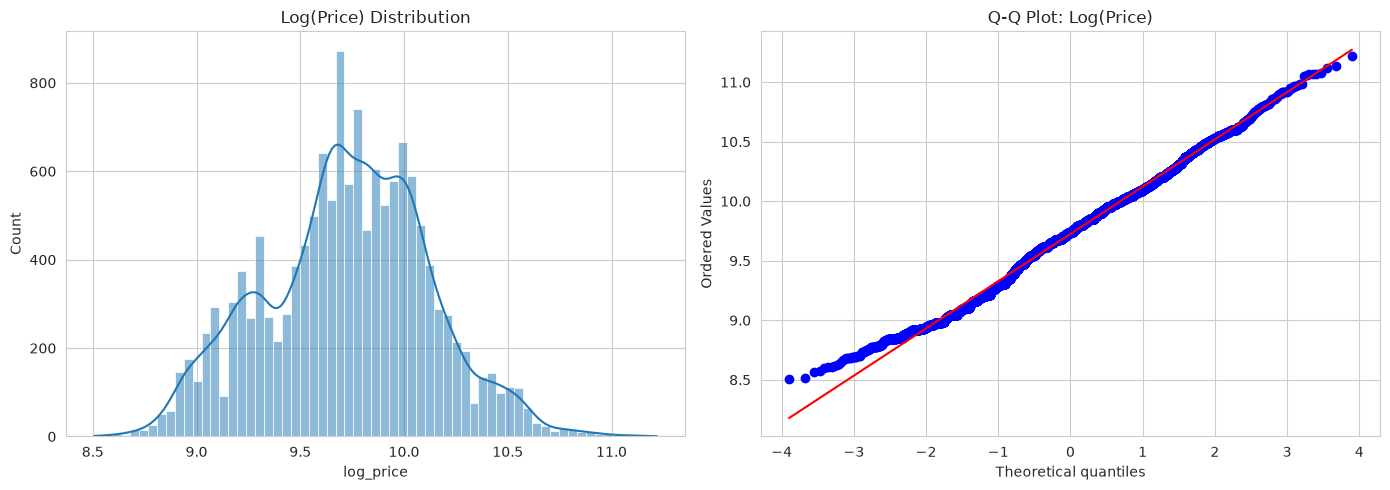

Skewness after log transform: -0.03548951812904353


In [21]:
# Transform the target feature
df['log_price'] = np.log1p(df['price'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['log_price'], kde=True, ax=axes[0])
axes[0].set_title('Log(Price) Distribution')
stats.probplot(df['log_price'], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot: Log(Price)')
plt.tight_layout()
plt.show()

print('Skewness after log transform:', df['log_price'].skew())


### **2.2 Correlation analysis** <font color = red> [6 marks] </font>

#### **2.2.1** <font color =red> [3 marks] </font>
Plot the correlation map between features and target variable.

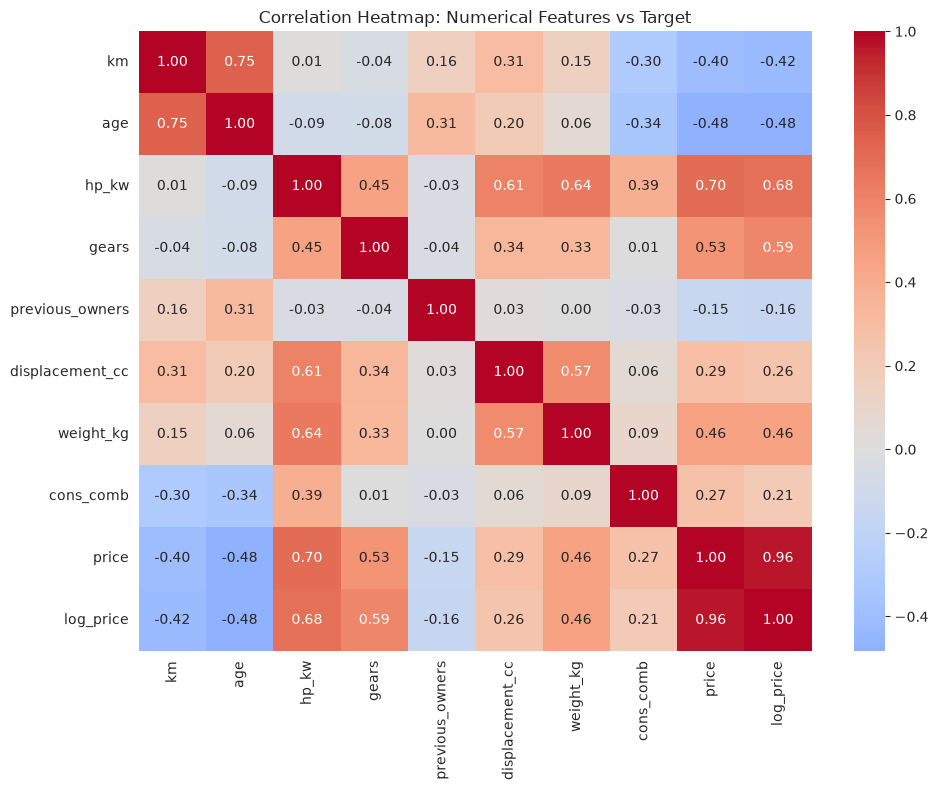

In [22]:
# Visualise correlation
corr_cols = numerical_features + ['price', 'log_price']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap: Numerical Features vs Target')
plt.tight_layout()
plt.show()


#### **2.2.2** <font color =red> [3 marks] </font>
Analyse correlation between categorical features and target variable.

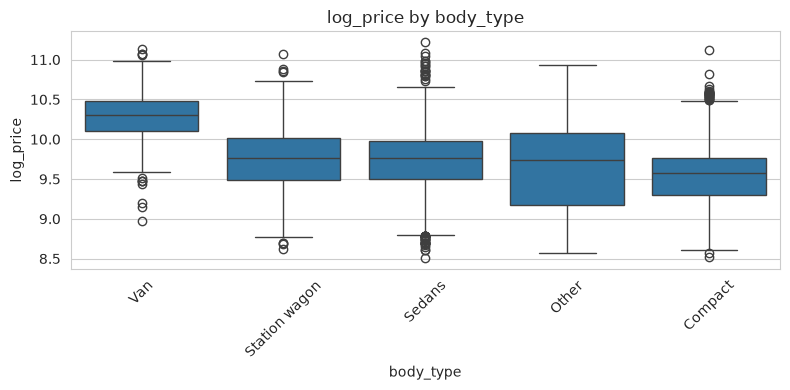

body_type
Van              30790.629932
Station wagon    18646.015272
Sedans           17675.357676
Other            17371.777778
Compact          15153.560148
Name: price, dtype: float64



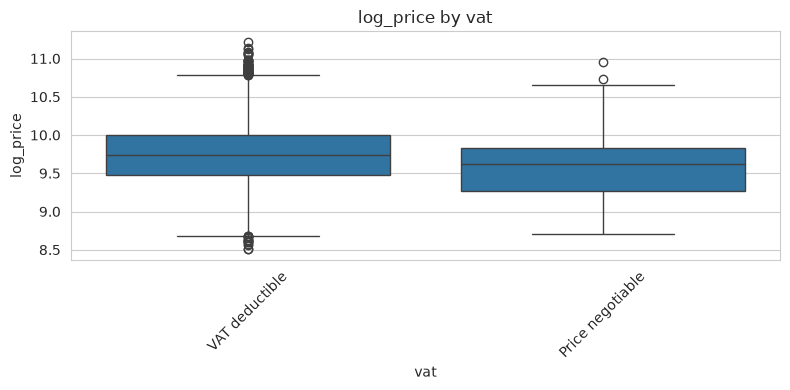

vat
VAT deductible      18260.229704
Price negotiable    15480.591912
Name: price, dtype: float64



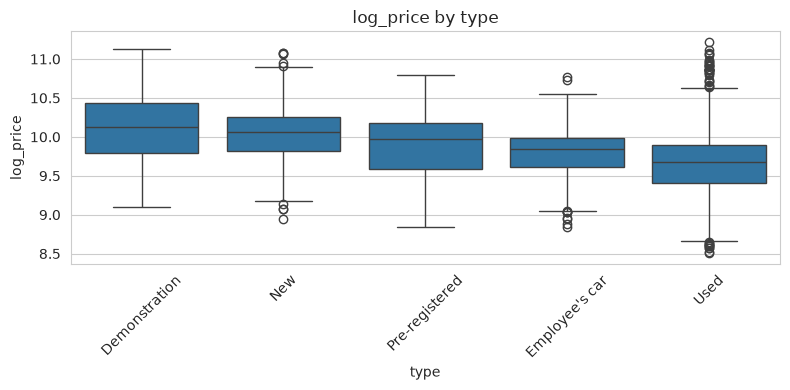

type
Demonstration     26021.249022
New               24062.222790
Pre-registered    21077.724976
Employee's car    18382.721547
Used              16375.263862
Name: price, dtype: float64



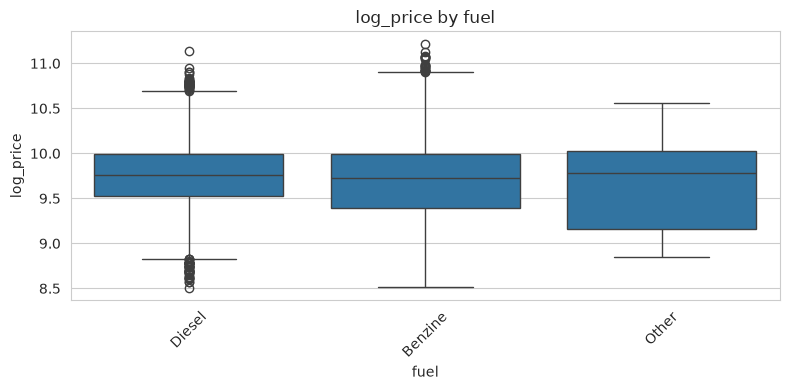

fuel
Diesel     18344.191419
Benzine    17893.938211
Other      17406.446154
Name: price, dtype: float64



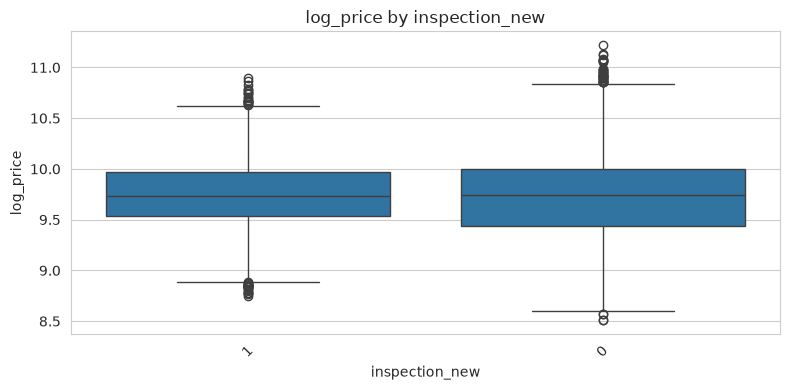

inspection_new
1    18135.282466
0    18089.145204
Name: price, dtype: float64



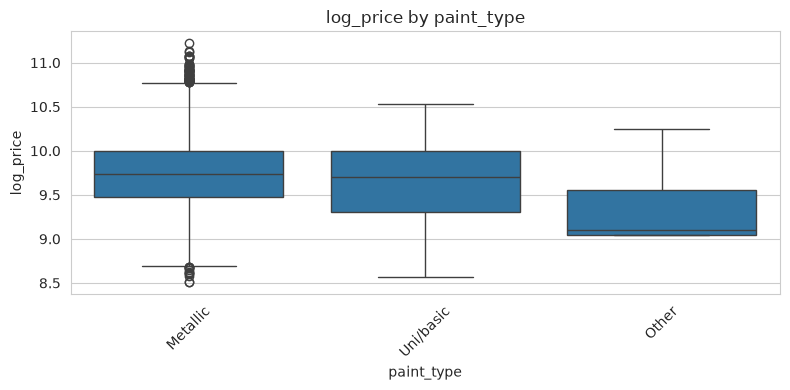

paint_type
Metallic     18150.512498
Uni/basic    16981.302368
Other        12360.000000
Name: price, dtype: float64



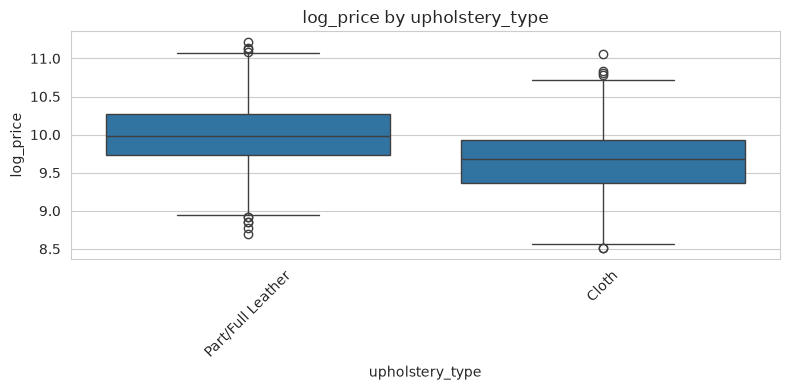

upholstery_type
Part/Full Leather    23411.920878
Cloth                16484.043048
Name: price, dtype: float64



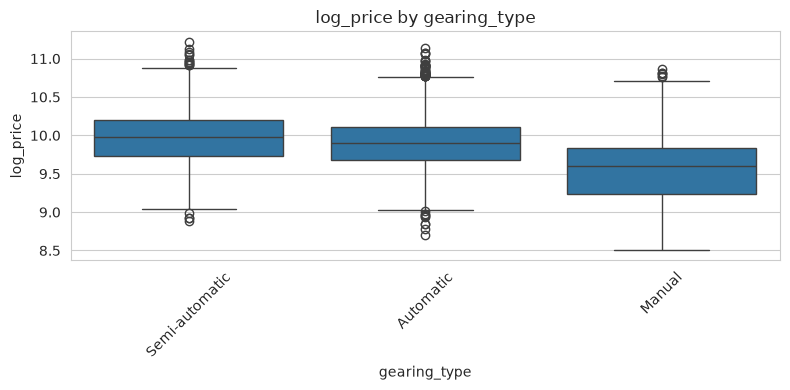

gearing_type
Semi-automatic    23281.364224
Automatic         21156.677819
Manual            15002.743501
Name: price, dtype: float64



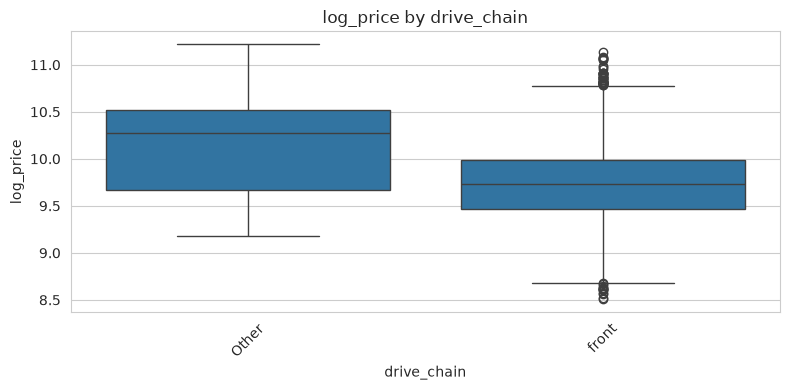

drive_chain
Other    28671.771429
front    17969.463780
Name: price, dtype: float64



In [23]:
# Comparing average values of target for different categories
for col in categorical_features:
    plt.figure(figsize=(8, 4))
    order = df.groupby(col)['log_price'].mean().sort_values(ascending=False).index
    sns.boxplot(data=df, x=col, y='log_price', order=order)
    plt.title(f'log_price by {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print(df.groupby(col)['price'].mean().sort_values(ascending=False))
    print()


### **2.3 Outlier analysis** <font color = red> [5 marks] </font>

#### **2.3.1** <font color =red> [2 marks] </font>
Identify potential outliers in the data.

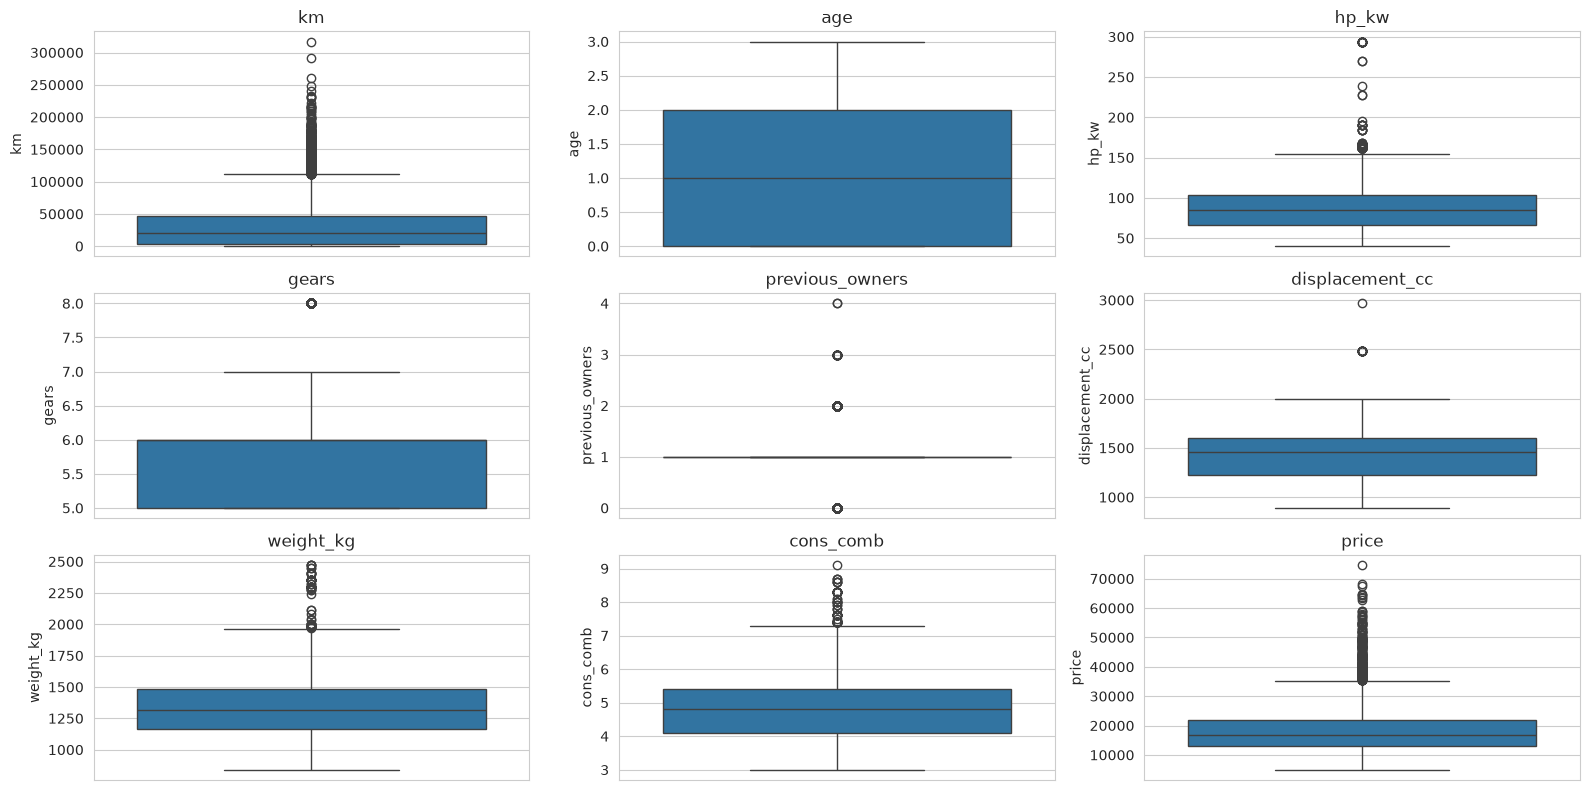

km: 657 outliers (4.61%)
age: 0 outliers (0.00%)
hp_kw: 298 outliers (2.09%)
gears: 203 outliers (1.43%)
previous_owners: 1542 outliers (10.83%)
displacement_cc: 21 outliers (0.15%)
weight_kg: 73 outliers (0.51%)
cons_comb: 111 outliers (0.78%)
price: 464 outliers (3.26%)


In [24]:
# Outliers present in each column
plt.figure(figsize=(16, 8))
for i, col in enumerate(numerical_features + ['price'], 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

# IQR-based outlier count
for col in numerical_features + ['price']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col}: {n_outliers} outliers ({n_outliers/len(df)*100:.2f}%)')


#### **2.3.2** <font color =red> [3 marks] </font>
Handle the outliers suitably.

In [25]:
# Handle outliers
cols_to_cap = ['km', 'hp_kw', 'displacement_cc', 'weight_kg', 'cons_comb', 'price']
cols_to_cap = [c for c in cols_to_cap if c in df.columns]

for col in cols_to_cap:
    lower = df[col].quantile(0.01)
    upper = df[col].quantile(0.99)
    df[col] = df[col].clip(lower, upper)

# Recompute log target after capping
df['log_price'] = np.log1p(df['price'])
print(df[cols_to_cap].describe())

                  km         hp_kw  displacement_cc     weight_kg  \
count   14242.000000  14242.000000     14242.000000  14242.000000   
mean    32348.284147     88.501194      1432.133198   1340.396082   
std     35889.683242     25.452747       275.247009    192.875975   
min         1.000000     51.000000       898.000000   1063.000000   
25%      3898.000000     66.000000      1229.000000   1165.000000   
50%     21000.000000     85.000000      1461.000000   1320.000000   
75%     47000.000000    103.000000      1598.000000   1487.000000   
max    157000.000000    165.000000      1997.000000   1845.000000   

          cons_comb         price  
count  14242.000000  14242.000000  
mean       4.821763  18030.804281  
std        0.842797   7110.341441  
min        3.300000   7000.000000  
25%        4.100000  12950.000000  
50%        4.800000  16950.000000  
75%        5.400000  21900.000000  
max        7.100000  40944.990000  


### **2.4 Feature Engineering** <font color = red> [11 marks] </font>

#### **2.4.1**
Fix any redundant columns and create new ones if needed.

In [26]:
# Fix/create columns as needed
drop_cols = ['make_model']  # high-cardinality identifier; consider brand extraction instead
df['brand'] = df['make_model'].str.split(' ').str[0] if 'make_model' in df.columns else np.nan

if 'make_model' in df.columns:
    df = df.drop(columns=['make_model'])

# Example engineered feature: power-to-weight ratio
if {'hp_kW', 'Weight_kg'}.issubset(df.columns):
    df['power_to_weight'] = df['hp_kW'] / df['Weight_kg']

print(df.columns.tolist())


['body_type', 'price', 'vat', 'km', 'type', 'fuel', 'gears', 'comfort_convenience', 'entertainment_media', 'extras', 'safety_security', 'age', 'previous_owners', 'hp_kw', 'inspection_new', 'paint_type', 'upholstery_type', 'gearing_type', 'displacement_cc', 'weight_kg', 'drive_chain', 'cons_comb', 'log_price', 'brand']


#### **2.4.2** <font color =red> [4 marks] </font>
Analysis and feature engineering on `['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']`.

These columns contains lists of features present. Decide on how to include these features in the predictors.

In [27]:
# Check unique values in each feature spec column
spec_cols = ['comfort_convenience', 'entertainment_media', 'extras', 'safety_security']
spec_cols = [c for c in spec_cols if c in df.columns]

spec_value_counts = {}
for col in spec_cols:
    items = df[col].dropna().str.split(',').explode().str.strip()
    counts = items.value_counts()
    spec_value_counts[col] = counts
    print(f'--- {col}: {len(counts)} unique features ---')
    print(counts.head(10))
    print()


--- comfort_convenience: 38 unique features ---
comfort_convenience
Air conditioning                      13594
Power windows                         13312
Electrical side mirrors               11309
Multi-function steering wheel         10652
Cruise control                        10446
Park Distance Control                  9642
Parking assist system sensors rear     9178
Leather steering wheel                 8885
Start-stop system                      8432
Automatic climate control              8409
Name: count, dtype: int64

--- entertainment_media: 10 unique features ---
entertainment_media
Radio                   11862
On-board computer       11855
Bluetooth               11381
Hands-free equipment     9347
USB                      8054
MP3                      5705
CD player                4614
Digital radio            2076
Sound system             1971
Television                 39
Name: count, dtype: int64

--- extras: 17 unique features ---
extras
Alloy wheels           12494

Out of these features, we will check the ones which are present in most of the cars or are absent from most of the cars. These kinds of features can be removed as they just increase the dimensionality without explaining the variance.

In [28]:
# Drop features from df
n = len(df)
for col in spec_cols:
    counts = spec_value_counts[col]
    keep_items = counts[(counts / n >= 0.05) & (counts / n <= 0.95)].index.tolist()
    for item in keep_items:
        flag_col = f'{col}_{item.replace(" ", "_")}'
        df[flag_col] = df[col].fillna('').apply(lambda x, it=item: int(it in x))
    df = df.drop(columns=[col])

print(df.columns.tolist())



['body_type', 'price', 'vat', 'km', 'type', 'fuel', 'gears', 'age', 'previous_owners', 'hp_kw', 'inspection_new', 'paint_type', 'upholstery_type', 'gearing_type', 'displacement_cc', 'weight_kg', 'drive_chain', 'cons_comb', 'log_price', 'brand', 'comfort_convenience_Power_windows', 'comfort_convenience_Electrical_side_mirrors', 'comfort_convenience_Multi-function_steering_wheel', 'comfort_convenience_Cruise_control', 'comfort_convenience_Park_Distance_Control', 'comfort_convenience_Parking_assist_system_sensors_rear', 'comfort_convenience_Leather_steering_wheel', 'comfort_convenience_Start-stop_system', 'comfort_convenience_Automatic_climate_control', 'comfort_convenience_Rain_sensor', 'comfort_convenience_Navigation_system', 'comfort_convenience_Light_sensor', 'comfort_convenience_Armrest', 'comfort_convenience_Seat_heating', 'comfort_convenience_Hill_Holder', 'comfort_convenience_Parking_assist_system_sensors_front', 'comfort_convenience_Parking_assist_system_camera', 'comfort_conveni

#### **2.4.3** <font color =red> [3 marks] </font>
Perform feature encoding.

In [29]:
# Encode features
target_col = 'log_price'
drop_from_X = ['price', 'log_price']

X = df.drop(columns=[c for c in drop_from_X if c in df.columns])
y = df[target_col]

categorical_features_final = X.select_dtypes(include='object').columns.tolist()
X = pd.get_dummies(X, columns=categorical_features_final, drop_first=True)

print(X.shape)
X.head()


(14242, 99)


/tmp/ipykernel_30149/428385798.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_final = X.select_dtypes(include='object').columns.tolist()


,km,gears,age,previous_owners,hp_kw,inspection_new,displacement_cc,weight_kg,cons_comb,comfort_convenience_Power_windows,comfort_convenience_Electrical_side_mirrors,comfort_convenience_Multi-function_steering_wheel,comfort_convenience_Cruise_control,comfort_convenience_Park_Distance_Control,comfort_convenience_Parking_assist_system_sensors_rear,comfort_convenience_Leather_steering_wheel,comfort_convenience_Start-stop_system,comfort_convenience_Automatic_climate_control,comfort_convenience_Rain_sensor,comfort_convenience_Navigation_system,comfort_convenience_Light_sensor,comfort_convenience_Armrest,comfort_convenience_Seat_heating,comfort_convenience_Hill_Holder,comfort_convenience_Parking_assist_system_sensors_front,comfort_convenience_Parking_assist_system_camera,comfort_convenience_Lumbar_support,comfort_convenience_Heated_steering_wheel,comfort_convenience_Keyless_central_door_lock,comfort_convenience_Split_rear_seats,comfort_convenience_Electrically_adjustable_seats,comfort_convenience_Tinted_windows,comfort_convenience_Electric_tailgate,comfort_convenience_Electrically_heated_windshield,comfort_convenience_Seat_ventilation,comfort_convenience_Parking_assist_system_self-steering,entertainment_media_Radio,entertainment_media_On-board_computer,entertainment_media_Bluetooth,entertainment_media_Hands-free_equipment,entertainment_media_USB,entertainment_media_MP3,entertainment_media_CD_player,entertainment_media_Digital_radio,entertainment_media_Sound_system,extras_Alloy_wheels,extras_Voice_Control,extras_Touch_screen,extras_Sport_seats,extras_Roof_rack,extras_Catalytic_Converter,extras_Sport_suspension,extras_Sport_package,safety_security_ABS,safety_security_Driver-side_airbag,safety_security_Passenger-side_airbag,safety_security_Power_steering,safety_security_Electronic_stability_control,safety_security_Side_airbag,safety_security_Central_door_lock,safety_security_Isofix,safety_security_Traction_control,safety_security_Tire_pressure_monitoring_system,safety_security_Immobilizer,safety_security_Daytime_running_lights,safety_security_Fog_lights,safety_security_LED_Daytime_Running_Lights,safety_security_Xenon_headlights,safety_security_Emergency_brake_assistant,safety_security_LED_Headlights,safety_security_Lane_departure_warning_system,safety_security_Central_door_lock_with_remote_control,safety_security_Head_airbag,safety_security_Adaptive_headlights,safety_security_Traffic_sign_recognition,safety_security_Alarm_system,safety_security_Emergency_system,safety_security_Blind_spot_monitor,safety_security_Adaptive_Cruise_Control,safety_security_Rear_airbag,body_type_Other,body_type_Sedans,body_type_Station wagon,body_type_Van,vat_VAT deductible,type_Employee's car,type_New,type_Pre-registered,type_Used,fuel_Diesel,fuel_Other,paint_type_Other,paint_type_Uni/basic,upholstery_type_Part/Full Leather,gearing_type_Manual,gearing_type_Semi-automatic,drive_chain_front,brand_Opel,brand_Renault
0,56013.0,7.0,3.0,2.0,66.0,1,1422.0,1220.0,3.8,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,False,True,False,False,True,False,False,False,True,True,False,False,False,False,False,False,True,False,False
1,80000.0,7.0,2.0,1.0,141.0,0,1798.0,1255.0,5.6,1,0,0,0,0,1,1,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,1,1,1,0,0,0,0,1,1,1,0,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False
2,83450.0,7.0,3.0,1.0,85.0,0,1598.0,1135.0,3.8,1,1,1,1,1,1,1,1,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,False,True,False,False,True,False,False,False,True,True,False,False,False,False,False,False,True,False,False
3,73000.0,6.0,3.0,1.0,66.0,0,1422.0,1195.0,3.8,1,1,1,0,0,0,1,1,0,1,1,1,1,1,1,0,0,1,0,0,1,0,0,0,0,0,0,1,1,1,1,1,1,1,0,1,1,1,0,1,0,0,0,0,1,1,1,1,1,1,1,1,0,1,1,0,0,0,0,0,0,

#### **2.4.4** <font color =red> [2 marks] </font>
Split the data into training and testing sets.

In [30]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)


(11393, 99) (2849, 99)


#### **2.4.5** <font color =red> [2 marks] </font>
Scale the features.

In [31]:
# Scale features
numeric_cols_to_scale = X_train.select_dtypes(include=np.number).columns.tolist()

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols_to_scale] = scaler.fit_transform(X_train[numeric_cols_to_scale])
X_test_scaled[numeric_cols_to_scale] = scaler.transform(X_test[numeric_cols_to_scale])



## **3 Linear Regression Models** <font color =red> [35 marks] </font>


### **3.1 Baseline Linear Regression Model** <font color =red> [10 marks] </font>

#### **3.1.1** <font color =red> [5 marks] </font>
Build and fit a basic linear regression model. Perform evaluation using suitable metrics.

In [32]:
# Initialise and train model
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](99,)","[-0.09, 0.02,-0.08,..., 0.01,-0.3 ,-0.35]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](99,)","['km','gears','age',...,'drive_chain_front','brand_Opel','brand_Renault']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.923
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,99
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,99


In [33]:
# Evaluate the model's performance
def evaluate(model, X_tr, y_tr, X_te, y_te, name='Model'):
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    metrics = {
        'Model': name,
        'Train_R2': r2_score(y_tr, pred_tr),
        'Test_R2': r2_score(y_te, pred_te),
        'Train_MAE': mean_absolute_error(y_tr, pred_tr),
        'Test_MAE': mean_absolute_error(y_te, pred_te),
        'Train_RMSE': np.sqrt(mean_squared_error(y_tr, pred_tr)),
        'Test_RMSE': np.sqrt(mean_squared_error(y_te, pred_te)),
    }
    return metrics

baseline_metrics = evaluate(lr, X_train_scaled, y_train, X_test_scaled, y_test, 'Baseline LR')
baseline_metrics


{'Model': 'Baseline LR',
 'Train_R2': 0.9140818425630265,
 'Test_R2': 0.9123270649460412,
 'Train_MAE': 0.08636085851942824,
 'Test_MAE': 0.08606688728462927,
 'Train_RMSE': np.float64(0.11505959001524495),
 'Test_RMSE': np.float64(0.11556446313585085)}

#### **3.1.2** <font color =red> [5 marks] </font>
Analyse residuals and check other assumptions of linear regression.

Check for linearity by analysing residuals vs predicted values

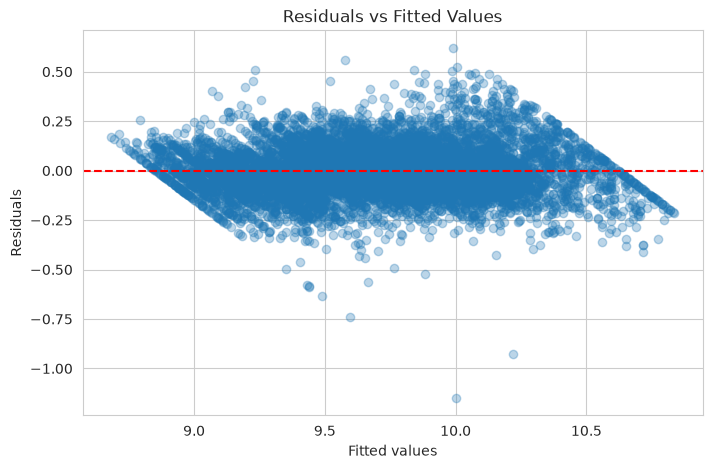

In [34]:
# Linearity check: Plot residuals vs fitted values
y_pred_train = lr.predict(X_train_scaled)
residuals = y_train - y_pred_train

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_train, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values')
plt.show()


Check normality in residual distribution

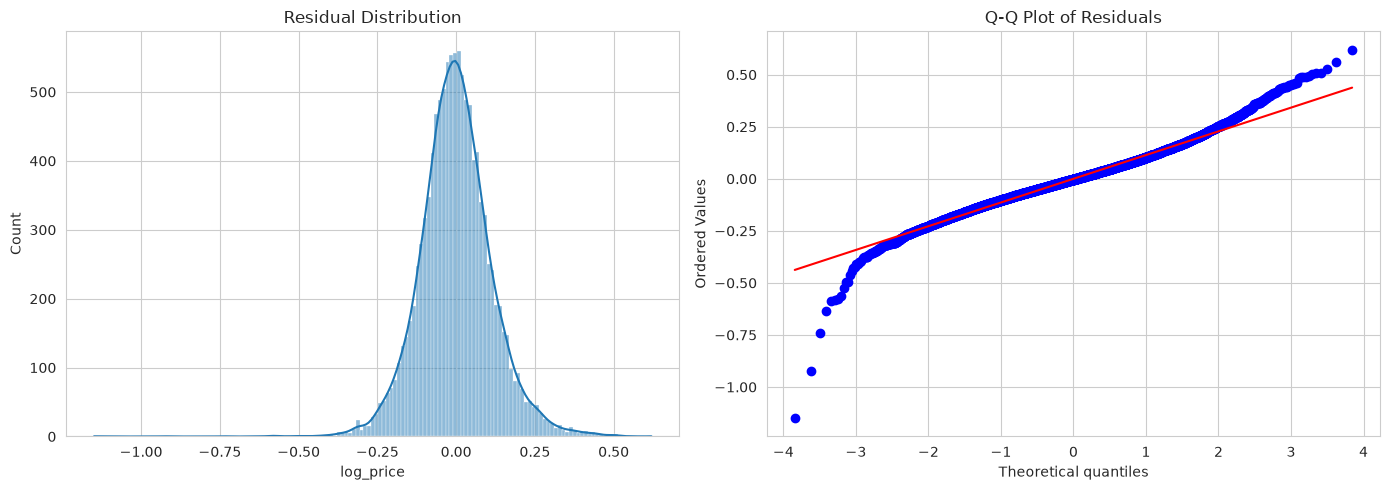

Shapiro-Wilk p-value: 0.00000


In [35]:
# Check the normality of residuals by plotting their distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title('Residual Distribution')
stats.probplot(residuals, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot of Residuals')
plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residuals.sample(min(5000, len(residuals)), random_state=1))
print(f'Shapiro-Wilk p-value: {shapiro_p:.5f}')


Check multicollinearity using Variance Inflation Factor (VIF) and handle features with high VIF.

In [36]:
X_train_scaled = X_train_scaled.astype(float)
X_test_scaled = X_test_scaled.astype(float)

vif_data = pd.DataFrame()
vif_data['feature'] = X_train_scaled.columns
vif_data['VIF'] = [variance_inflation_factor(X_train_scaled.values, i)
                    for i in range(X_train_scaled.shape[1])]

In [37]:
# Check for multicollinearity and handle
vif_data = pd.DataFrame()
vif_data['feature'] = X_train_scaled.columns
vif_data['VIF'] = [variance_inflation_factor(X_train_scaled.values, i)
                    for i in range(X_train_scaled.shape[1])]
vif_data = vif_data.sort_values('VIF', ascending=False)
print(vif_data.head(15))

# Iteratively drop features with VIF > 10 (highest first), refitting each time
high_vif_features = vif_data[vif_data['VIF'] > 10]['feature'].tolist()
print(f'\nFeatures with VIF > 10: {high_vif_features}')

X_train_scaled = X_train_scaled.drop(columns=high_vif_features, errors='ignore')
X_test_scaled = X_test_scaled.drop(columns=high_vif_features, errors='ignore')

lr = LinearRegression().fit(X_train_scaled, y_train)
baseline_metrics = evaluate(lr, X_train_scaled, y_train, X_test_scaled, y_test, 'Baseline LR (post-VIF)')
baseline_metrics



                                              feature        VIF
96                                  drive_chain_front  36.581841
84                                 vat_VAT deductible  18.103503
88                                          type_Used  15.872090
89                                        fuel_Diesel  10.508964
97                                         brand_Opel   8.591666
4                                               hp_kw   5.634716
82                            body_type_Station wagon   5.614705
6                                     displacement_cc   5.378682
81                                   body_type_Sedans   4.896598
14  comfort_convenience_Parking_assist_system_sens...   4.749482
98                                      brand_Renault   4.678861
94                                gearing_type_Manual   4.407124
13          comfort_convenience_Park_Distance_Control   4.038742
2                                                 age   3.917371
8                        

{'Model': 'Baseline LR (post-VIF)',
 'Train_R2': 0.90867223802924,
 'Test_R2': 0.9077823364520866,
 'Train_MAE': 0.08908875692542526,
 'Test_MAE': 0.08818418252472238,
 'Train_RMSE': np.float64(0.11862650967020155),
 'Test_RMSE': np.float64(0.11852189605422825)}

### **3.2 Ridge Regression Implementation** <font color =red> [10 marks] </font>

#### **3.2.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [38]:
# List of alphas to tune for Ridge regularisation
ridge_alphas = [0.001, 0.01, 0.1, 1, 5, 10, 20, 50, 100, 200, 500, 1000]


#### **3.2.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [39]:
# Applying Ridge regression
from sklearn.model_selection import cross_val_score

ridge_train_scores, ridge_test_scores = [], []
for a in ridge_alphas:
    model = Ridge(alpha=a)
    model.fit(X_train_scaled, y_train)
    train_mae = mean_absolute_error(y_train, model.predict(X_train_scaled))
    test_mae = mean_absolute_error(y_test, model.predict(X_test_scaled))
    ridge_train_scores.append(train_mae)
    ridge_test_scores.append(test_mae)


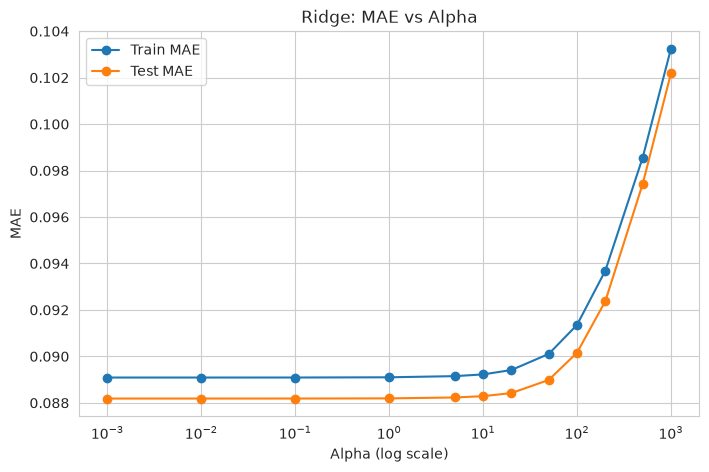

In [40]:
# Plot train and test scores against alpha
plt.figure(figsize=(8, 5))
plt.plot(ridge_alphas, ridge_train_scores, marker='o', label='Train MAE')
plt.plot(ridge_alphas, ridge_test_scores, marker='o', label='Test MAE')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('MAE')
plt.title('Ridge: MAE vs Alpha')
plt.legend()
plt.show()


Find the best alpha value.

In [41]:
# Best alpha value
best_ridge_alpha_coarse = ridge_alphas[int(np.argmin(ridge_test_scores))]
print('Best alpha (coarse):', best_ridge_alpha_coarse)

# Best score (negative MAE)
print('Best test MAE (coarse):', -min([-s for s in ridge_test_scores]))

Best alpha (coarse): 0.001
Best test MAE (coarse): 0.1021887596297265


We will get some best value of alpha above. This however is not the most accurate value but the best value from the given list. Now we have a rough estimate of the range that best alpha falls in. Let us do another iteration over the values in a smaller range.

#### **3.2.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [42]:
# Take a smaller range of alpha to test
ridge_alphas_fine = np.linspace(1e-6, 5, 40)


In [43]:
# Applying Ridge regression
ridge_train_scores_fine, ridge_test_scores_fine = [], []
for a in ridge_alphas_fine:
    model = Ridge(alpha=a)
    model.fit(X_train_scaled, y_train)
    train_mae = mean_absolute_error(y_train, model.predict(X_train_scaled))
    test_mae = mean_absolute_error(y_test, model.predict(X_test_scaled))
    ridge_train_scores_fine.append(train_mae)
    ridge_test_scores_fine.append(test_mae)


Plot the error-alpha graph again and find the actual optimal value for alpha.

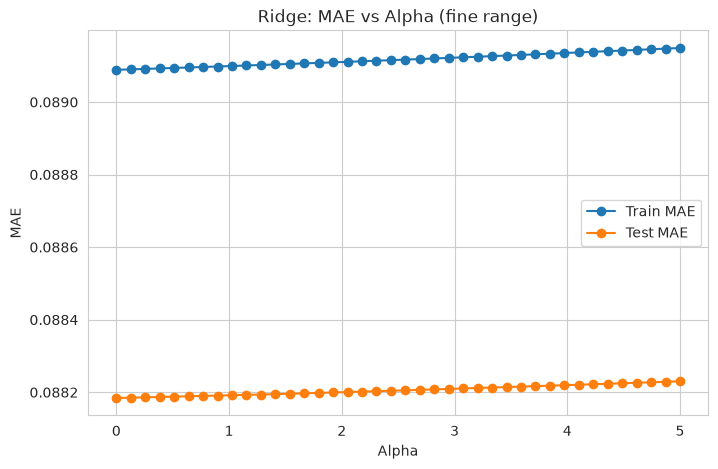

Best alpha (fine): 1e-06
Best test MAE (fine): 0.0881841825321159


In [44]:
# Plot train and test scores against alpha
plt.figure(figsize=(8, 5))
plt.plot(ridge_alphas_fine, ridge_train_scores_fine, marker='o', label='Train MAE')
plt.plot(ridge_alphas_fine, ridge_test_scores_fine, marker='o', label='Test MAE')
plt.xlabel('Alpha')
plt.ylabel('MAE')
plt.title('Ridge: MAE vs Alpha (fine range)')
plt.legend()
plt.show()

# Best alpha value
best_ridge_alpha = ridge_alphas_fine[int(np.argmin(ridge_test_scores_fine))]
print('Best alpha (fine):', best_ridge_alpha)

# Best score (negative MAE)
print('Best test MAE (fine):', min(ridge_test_scores_fine))


In [45]:
# Set best alpha for Ridge regression
# Fit the Ridge model to get the coefficients of the fitted model
ridge_final = Ridge(alpha=best_ridge_alpha)
ridge_final.fit(X_train_scaled, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",np.float64(1e-06)
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 's

In [46]:
# Show the coefficients for each feature
ridge_coefs = pd.Series(ridge_final.coef_, index=X_train_scaled.columns).sort_values()
ridge_coefs

brand_Renault                 -0.330244
brand_Opel                    -0.294991
age                           -0.092373
km                            -0.089945
gearing_type_Manual           -0.085512
                                 ...   
type_New                       0.052593
body_type_Other                0.058497
gearing_type_Semi-automatic    0.076016
hp_kw                          0.145895
body_type_Van                  0.235040
Length: 95, dtype: float64

In [47]:
# Evaluate the Ridge model on the test data
ridge_metrics = evaluate(ridge_final, X_train_scaled, y_train, X_test_scaled, y_test, 'Ridge')
ridge_metrics

{'Model': 'Ridge',
 'Train_R2': 0.90867223802924,
 'Test_R2': 0.907782336461048,
 'Train_MAE': 0.08908875693528219,
 'Test_MAE': 0.0881841825321159,
 'Train_RMSE': np.float64(0.11862650967020155),
 'Test_RMSE': np.float64(0.11852189604846947)}

### **3.3 Lasso Regression Implementation** <font color =red> [10 marks] </font>

#### **3.3.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [48]:
# List of alphas to tune for Lasso regularisation
lasso_alphas = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 10]

#### **3.3.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [49]:
# Initialise Lasso regression model
lasso_train_scores, lasso_test_scores = [], []
for a in lasso_alphas:
    model = Lasso(alpha=a, max_iter=10000)
    model.fit(X_train_scaled, y_train)
    train_mae = mean_absolute_error(y_train, model.predict(X_train_scaled))
    test_mae = mean_absolute_error(y_test, model.predict(X_test_scaled))
    lasso_train_scores.append(train_mae)
    lasso_test_scores.append(test_mae)

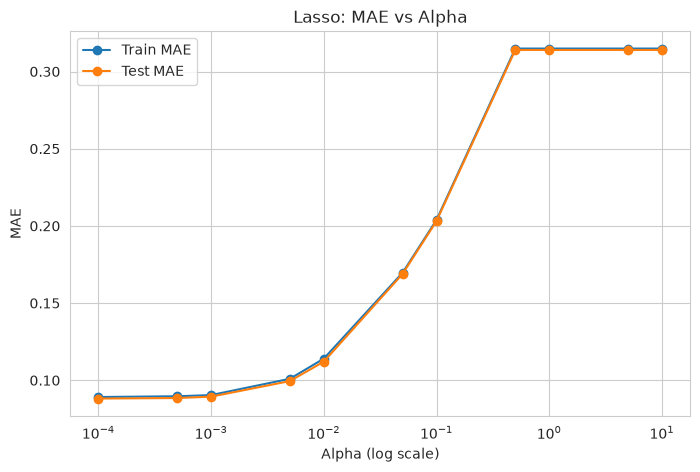

In [50]:
# Plot train and test scores against alpha
plt.figure(figsize=(8, 5))
plt.plot(lasso_alphas, lasso_train_scores, marker='o', label='Train MAE')
plt.plot(lasso_alphas, lasso_test_scores, marker='o', label='Test MAE')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('MAE')
plt.title('Lasso: MAE vs Alpha')
plt.legend()
plt.show()

In [51]:
# Best alpha value
best_lasso_alpha_coarse = lasso_alphas[int(np.argmin(lasso_test_scores))]
print('Best alpha (coarse):', best_lasso_alpha_coarse)

# Best score (negative MAE)
print('Best test MAE (coarse):', min(lasso_test_scores))

Best alpha (coarse): 0.0001
Best test MAE (coarse): 0.08816009566789731


#### **3.3.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [52]:
# List of alphas to tune for Lasso regularization
lasso_alphas_fine = np.linspace(1e-6, 0.005, 30)


In [53]:
# Tuning Lasso hyperparameters
lasso_train_scores_fine, lasso_test_scores_fine = [], []
for a in lasso_alphas_fine:
    model = Lasso(alpha=a, max_iter=10000)
    model.fit(X_train_scaled, y_train)
    train_mae = mean_absolute_error(y_train, model.predict(X_train_scaled))
    test_mae = mean_absolute_error(y_test, model.predict(X_test_scaled))
    lasso_train_scores_fine.append(train_mae)
    lasso_test_scores_fine.append(test_mae)


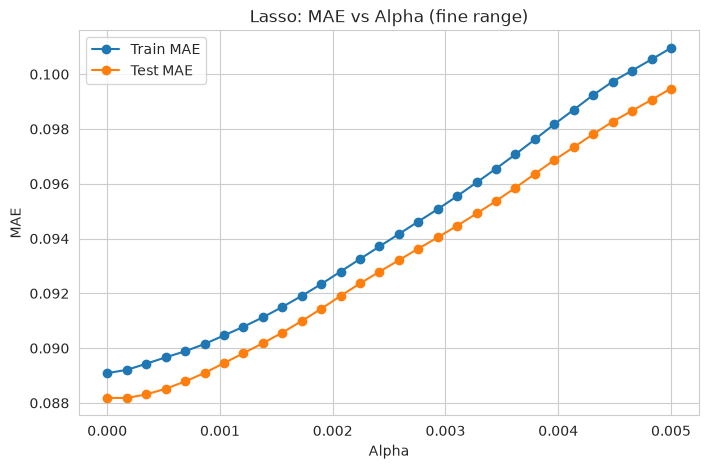

In [54]:
# Plot train and test scores against alpha
plt.figure(figsize=(8, 5))
plt.plot(lasso_alphas_fine, lasso_train_scores_fine, marker='o', label='Train MAE')
plt.plot(lasso_alphas_fine, lasso_test_scores_fine, marker='o', label='Test MAE')
plt.xlabel('Alpha')
plt.ylabel('MAE')
plt.title('Lasso: MAE vs Alpha (fine range)')
plt.legend()
plt.show()


In [55]:
# Best alpha value
best_lasso_alpha = lasso_alphas_fine[int(np.argmin(lasso_test_scores_fine))]
print('Best alpha (fine):', best_lasso_alpha)

# Best score (negative MAE)
print('Best test MAE (fine):', min(lasso_test_scores_fine))


Best alpha (fine): 0.0001733793103448276
Best test MAE (fine): 0.08818003439807337


In [56]:
# Set best alpha for Lasso regression
lasso_final = Lasso(alpha=best_lasso_alpha, max_iter=10000)

# Fit the Lasso model on scaled training data
lasso_final.fit(X_train_scaled, y_train)

# Get the coefficients of the fitted model
lasso_coefs = pd.Series(lasso_final.coef_, index=X_train_scaled.columns).sort_values()


In [57]:
# Check the coefficients for each feature
lasso_coefs


brand_Renault                 -0.318742
brand_Opel                    -0.289671
age                           -0.092897
km                            -0.089857
gearing_type_Manual           -0.084415
                                 ...   
type_New                       0.049299
weight_kg                      0.051469
gearing_type_Semi-automatic    0.070345
hp_kw                          0.147329
body_type_Van                  0.214895
Length: 95, dtype: float64

In [58]:
# Evaluate the Lasso model on the test data
lasso_metrics = evaluate(lasso_final, X_train_scaled, y_train, X_test_scaled, y_test, 'Lasso')
lasso_metrics


{'Model': 'Lasso',
 'Train_R2': 0.9085244413729812,
 'Test_R2': 0.9077807531110478,
 'Train_MAE': 0.08920649117618407,
 'Test_MAE': 0.08818003439807337,
 'Train_RMSE': np.float64(0.11872245811748194),
 'Test_RMSE': np.float64(0.11852291353704718)}

### **3.4 Regularisation Comparison & Analysis** <font color =red> [5 marks] </font>

#### **3.4.1** <font color =red> [2 marks] </font>
Compare the evaluation metrics for each model.

In [59]:
# Compare metrics for each model
comparison_df = pd.DataFrame([baseline_metrics, ridge_metrics, lasso_metrics]).set_index('Model')
comparison_df


,Train_R2,Test_R2,Train_MAE,Test_MAE,Train_RMSE,Test_RMSE
Model,,,,,,
Baseline LR (post-VIF),0.908672,0.907782,0.089089,0.088184,0.118627,0.118522
Ridge,0.908672,0.907782,0.089089,0.088184,0.118627,0.118522
Lasso,0.908524,0.907781,0.089206,0.088180,0.118722,0.118523


#### **3.4.2** <font color =red> [3 marks] </font>
Compare the coefficients for the three models.

Also visualise a few of the largest coefficients and the coefficients of features dropped by Lasso.

Features eliminated by Lasso: 5 of 95


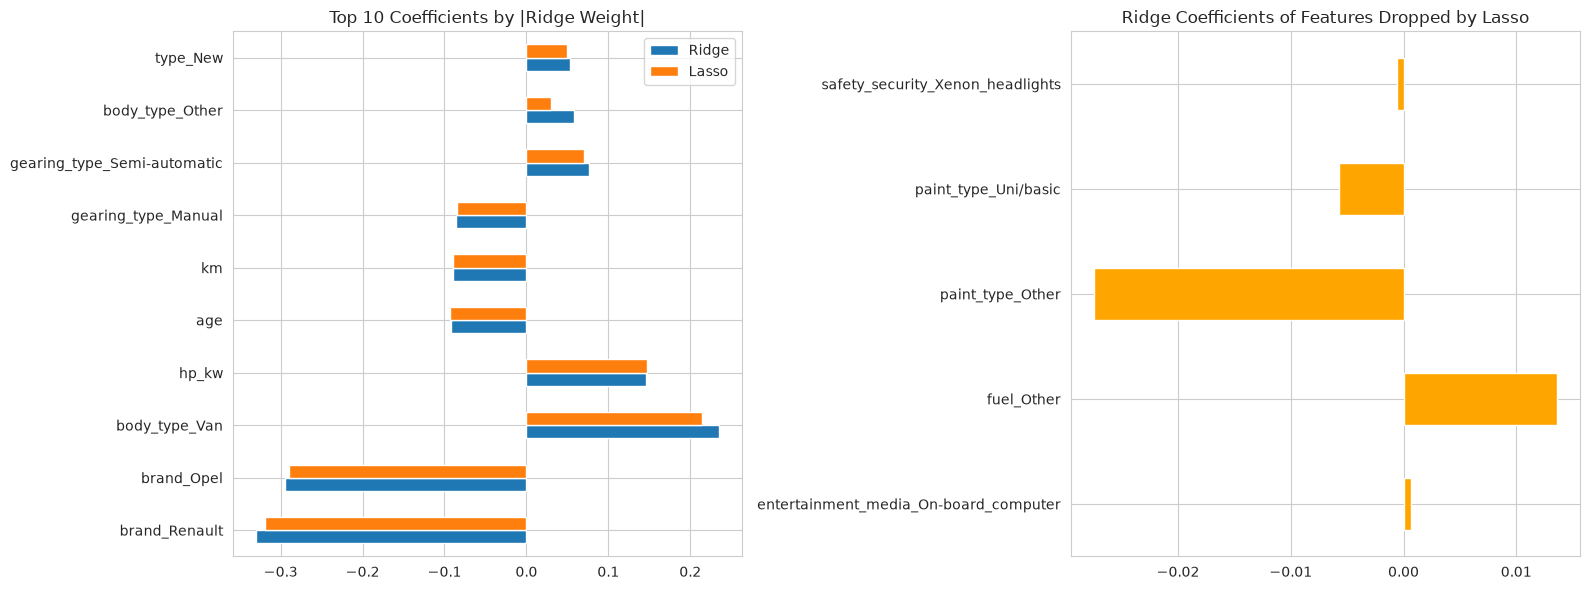

In [60]:
# Compare highest coefficients and coefficients of eliminated features
coef_compare = pd.DataFrame({
    'Ridge': ridge_coefs,
    'Lasso': lasso_coefs
})

top_features = coef_compare['Ridge'].abs().sort_values(ascending=False).head(10).index
dropped_by_lasso = coef_compare[coef_compare['Lasso'] == 0].index

print(f'Features eliminated by Lasso: {len(dropped_by_lasso)} of {len(coef_compare)}')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
coef_compare.loc[top_features].plot(kind='barh', ax=axes[0])
axes[0].set_title('Top 10 Coefficients by |Ridge Weight|')

if len(dropped_by_lasso) > 0:
    coef_compare.loc[dropped_by_lasso].head(15)['Ridge'].plot(kind='barh', ax=axes[1], color='orange')
    axes[1].set_title('Ridge Coefficients of Features Dropped by Lasso')
else:
    axes[1].text(0.5, 0.5, 'No features eliminated by Lasso', ha='center', va='center')
    axes[1].set_title('Ridge Coefficients of Features Dropped by Lasso')

plt.tight_layout()
plt.show()


## **4 Conclusion & Key Takeaways**  <font color =red> [10 marks] </font>

What did you notice by performing regularisation? Did the model performance improve? If not, then why? Did you find overfitting or not? Was the data sufficent? Is a linear model sufficient?

#### **4.1 Conclude with outcomes and insights gained** <font color =red> [10 marks] </font>